In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import src.helper
import xarray as xr

In [3]:
example = "./five_days_ocean_velocity/soda3.15.2_5dy_ocean_reg_2017_01_03.nc"
ds = xr.open_dataset(example, engine="netcdf4", decode_timedelta=False)

In [4]:
ds.u.isel(st_ocean=0)

<xarray.DataArray 'u' (time: 1, yu_ocean: 330, xu_ocean: 720)> Size: 950kB
[237600 values with dtype=float32]
Coordinates:
  * time      (time) datetime64[ns] 8B 2017-01-03T13:00:00
  * xu_ocean  (xu_ocean) float64 6kB 0.5 1.0 1.5 2.0 ... 358.5 359.0 359.5 360.0
  * yu_ocean  (yu_ocean) float64 3kB -74.5 -74.0 -73.5 -73.0 ... 89.0 89.5 90.0
    st_ocean  float64 8B 5.034
Attributes:
    standard_name:  sea_water_x_velocity
    long_name:      i-current
    units:          m/sec
    cell_methods:   time: mean
    time_avg_info:  average_T1,average_T2,average_DT

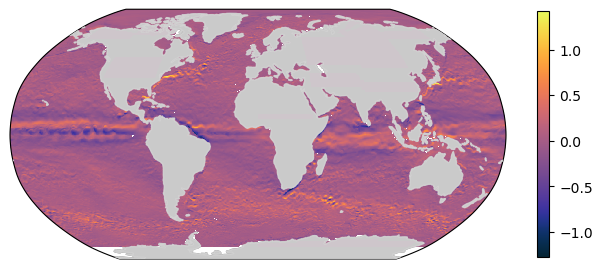

In [5]:
fig = plt.figure(figsize=(8, 8))
# Define the projection for a high-resolution South Polar Stereographic map
high_res_proj = ccrs.Robinson()
high_res_proj.threshold = 1e3
ax = fig.add_subplot(111, projection=high_res_proj)
ax.add_feature(cfeature.LAND, color="grey")
im = ax.pcolormesh(
    ds.u.isel(st_ocean=0, time=0).xu_ocean,
    ds.u.isel(st_ocean=0, time=0).yu_ocean,
    ds.u.isel(st_ocean=0, time=0).values,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

In [6]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    """
    lathelp = np.arange(-75, -60, 5)
    gl.ylocator = mticker.FixedLocator(lathelp)
    lonhelp = np.arange(-80, -10, 10)
    gl.xlocator = mticker.FixedLocator(lonhelp)
    """

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

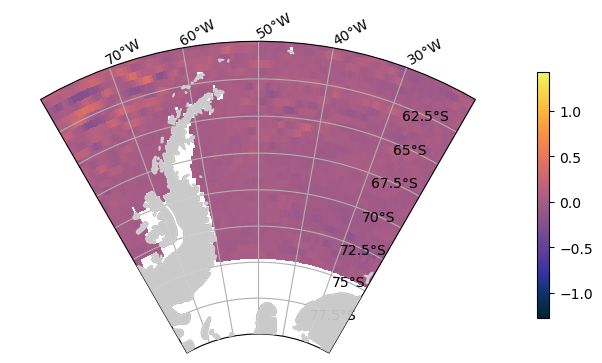

In [7]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    ds.u.isel(st_ocean=0, time=0).xu_ocean,
    ds.u.isel(st_ocean=0, time=0).yu_ocean,
    ds.u.isel(st_ocean=0, time=0).values,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4);

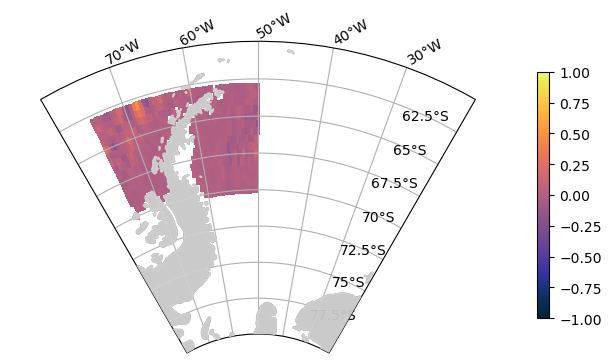

In [8]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")

surface_velocity_at_mooring = ds.sel(yu_ocean=slice(-70, -63), xu_ocean=slice(-75 + 360, -50 + 360))
boxlat = surface_velocity_at_mooring.variables["yu_ocean"][:]  # latitude grid points
boxlon = surface_velocity_at_mooring.variables["xu_ocean"][:]  # longitude grid points

# assert boxlat.size != 1
# assert boxlon.size != 1

# Compute monthly statistics averaged over space
im = ax.pcolormesh(
    boxlon,
    boxlat,
    surface_velocity_at_mooring.isel(st_ocean=0, time=0).v,
    vmin=-1,
    vmax=1,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.thermal,
    shading="nearest",
)
fig.colorbar(im, orientation="vertical", shrink=0.4);

# Cut to values at moorings

In [9]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
list_of_moorings = src.helper.load_pickle(name="../data/mooring/list_of_moorings.pkl")
width_in_lon = 1.5
height_in_lat = 1

mooring_bins = {}
for name, mooring in zip(mooring_names, list_of_moorings):
    boxlats = np.array(
        [mooring.location.lat + height_in_lat / 2, mooring.location.lat - height_in_lat / 2]
    )
    boxlons = np.array(
        [mooring.location.lon - width_in_lon / 2, mooring.location.lon + width_in_lon / 2]
    )
    mooring_bins[name] = {"lat": boxlats, "lon": boxlons}
    print(mooring_bins[name])

{'lat': array([-62.9032, -63.9032]), 'lon': array([-53.037, -51.537])}
{'lat': array([-63.0145, -64.0145]), 'lon': array([-52.3857, -50.8857])}
{'lat': array([-63.156, -64.156]), 'lon': array([-51.5613, -50.0613])}
{'lat': array([-63.2783, -64.2783]), 'lon': array([-50.8397, -49.3397])}
{'lat': array([-63.417, -64.417]), 'lon': array([-50.0182, -48.5182])}
{'lat': array([-63.5665, -64.5665]), 'lon': array([-49.1305, -47.6305])}
{'lat': array([-63.7157, -64.7157]), 'lon': array([-48.2403, -46.7403])}


In [10]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

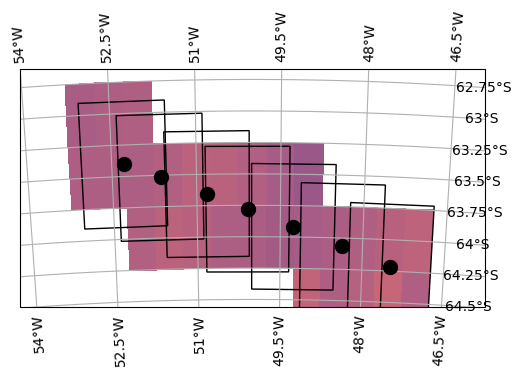

In [11]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

for name, bounds in mooring_bins.items():
    surface_velocity_at_mooring = ds.sel(
        yu_ocean=slice(bounds["lat"][1], bounds["lat"][0]),
        xu_ocean=slice(bounds["lon"][0] + 360, bounds["lon"][1] + 360),
    )
    boxlat = surface_velocity_at_mooring.variables["yu_ocean"][:]  # latitude grid points
    boxlon = surface_velocity_at_mooring.variables["xu_ocean"][:]  # longitude grid points

    try:
        assert boxlat.size != 1
        assert boxlon.size != 1
    except AssertionError as e:
        print("Bins too small to contain more than 1 data point in all directions")
        print(f"size = {(boxlat.size, boxlon.size)}")
        raise e

    # Compute monthly statistics averaged over space
    im = ax.pcolormesh(
        boxlon - 360,
        boxlat,
        surface_velocity_at_mooring.isel(st_ocean=0, time=0).v,
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree(),
        cmap=cmocean.cm.thermal,
        shading="nearest",
    )

# im = ax.pcolormesh(ds.u.isel(st_ocean=0, time=0).xu_ocean, ds.u.isel(st_ocean=0, time=0).yu_ocean, ds.u.isel(st_ocean=0, time=0).values, transform=ccrs.PlateCarree(), cmap = cmocean.cm.thermal, shading = "nearest")

for name, mooring in zip(mooring_names, list_of_moorings):
    ax.plot(mooring.location.lon, mooring.location.lat, "k.", ms=20, transform=ccrs.PlateCarree())

for mooring in list_of_moorings:
    patch = mpatches.Rectangle(
        xy=[mooring.location.lon - width_in_lon / 2, mooring.location.lat - height_in_lat / 2],
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )

    assert np.all((patch.get_center() - (mooring.location.lon, mooring.location.lat)) < 0.01)
    ax.add_patch(patch)

# Read out data for all moorings and months

In [48]:
filepaths = sorted(
    src.helper.get_filepaths_from_directory("./five_days_ocean_velocity/", inclusive=".nc")
)
print(f"{len(filepaths)} files found")

73 files found


In [49]:
for year in [2017, 2018]:
    dict_of_velocities = {name: [] for name in mooring_names}  # pd.DataFrame(index = mooring_names)
    timestamps = []
    for file_path in filepaths:
        if str(year) not in file_path:
            continue
        data_set = xr.open_dataset(file_path, engine="netcdf4", decode_timedelta=False).isel(
            st_ocean=slice(0, 2)
        )
        timestamps.append(data_set.time.values)
        for name, bounds in mooring_bins.items():
            subset = data_set.sel(
                yu_ocean=slice(bounds["lat"][1], bounds["lat"][0]),
                xu_ocean=slice(bounds["lon"][0] + 360, bounds["lon"][1] + 360),
            )
            surface_velocity_at_mooring = subset.u + 1j * subset.v

            boxlat = subset.variables["yu_ocean"][:]  # latitude grid points
            boxlon = subset.variables["xu_ocean"][:]  # longitude grid points
            try:
                assert boxlat.size != 1
                assert boxlon.size != 1
            except AssertionError as e:
                print("Bins too small to contain more than 1 data point in all directions")
                print(f"size = {(boxlat.size, boxlon.size)}")
                raise e

            surface_velocity_at_mooring = np.squeeze(
                surface_velocity_at_mooring.mean(dim=["yu_ocean", "xu_ocean", "st_ocean"]).values
            )

            dict_of_velocities[name].append(surface_velocity_at_mooring)

    sea_surface_velocities = pd.DataFrame(
        index=np.squeeze(np.array(timestamps)), data=dict_of_velocities
    )
    if sea_surface_velocities.empty == True:
        print(f"no data found for {year}")
    else:
        sea_surface_velocities.to_csv(f"./{year}_5days_surface_velocity.csv")

no data found for 2017


In [51]:
sea_surface_velocities

,A,B,C,D,E,F,G
2018-01-03 13:00:00,(-0.078039646+0.14103442j),(0.084337436+0.07988153j),(0.040279586+0.030144086j),(-0.02419728-0.050915744j),(-0.047247183-0.058175225j),(0.012346606+0.029698849j),(0.038113598+0.04423103j)
2018-01-08 13:00:00,(-0.07620014+0.14748923j),(0.09654523+0.090934j),(0.052498695+0.03866383j),(-0.015904939-0.064066984j),(-0.036014754-0.059801597j),(0.0274735+0.030097576j),(0.048632037+0.04520454j)
2018-01-13 13:00:00,(-0.07792164+0.13953839j),(0.082361765+0.0857823j),(0.047022205+0.03941111j),(-0.023126295-0.0686458j),(-0.053739455-0.072810434j),(0.0018156562+0.023733027j),(0.03601527+0.030201474j)
2018-01-18 13:00:00,(-0.06823612+0.124152355j),(0.08939403+0.078754164j),(0.05827804+0.03995828j),(-0.0029066869-0.062323213j),(-0.033198986-0.08319359j),(0.013916482+0.022410015j),(0.03751942+0.0319311j)
2018-01-23 13:00:00,(-0.0698812+0.13702388j),(0.080996566+0.10037265j),(0.057149965+0.07119287j),(-0.010678672-0.036469806j),(-0.04031043-0.061682653j),(0.026829531+0.04153117j),(0.03765421+0.05343889j)
...,...,...,...,...,...,...,...
2018-12-09 13:00:00,(-0.002725328+0.041049544j),(0.020859817+0.040361162j),(0.029834496+0.046940167j),(0.043204393+0.06969863j),(0.030839568+0.065678j),(0.014381756+0.034585427j),(0.016913002+0.039139356j)
2018-12-14 13:00:00,(0.0017608344+0.09104333j),(0.04226355+0.085540004j),(0.05007577+0.089375466j),(0.06111604+0.10688939j),(0.046685178+0.10217782j),(0.031870876+0.056964945j),(0.034987763+0.056667816j)
2018-12-19 13:00:00,(-0.032562237+0.06967458j),(0.038998727+0.05625735j),(0.047418583+0.06294955j),(0.057349082+0.087435246j),(0.040458392+0.083642244j),(0.020621616+0.035980005j),(0.020685531+0.03113745j)
2018-12-24 13:00:00,(-0.015449293+0.046152744j),(0.04445364+0.039004344j),(0.052942663+0.04456666j),(0.053360824+0.06188013j),(0.035259005+0.05485822j),(0.022140747+0.012906373j),(0.022020953+0.0060140244j)


# Sanity check

In [52]:
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

In [53]:
cmap = plt.cm.viridis
number_of_moorings = len(list_of_moorings)
color_list = [cmap(i / number_of_moorings) for i in range(number_of_moorings)]
# color_list.append("xkcd:rose")
discrete_cmap = mcolors.LinearSegmentedColormap.from_list(
    "mooring_ids", color_list, N=number_of_moorings
)

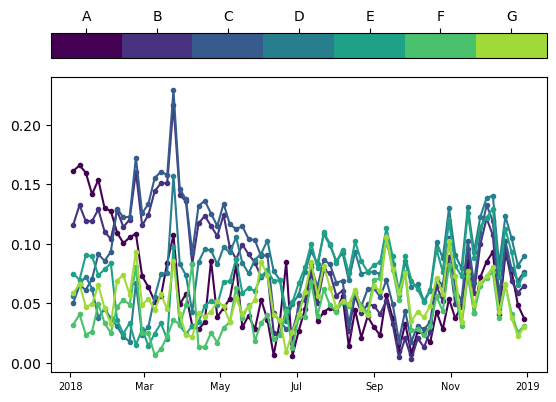

In [55]:
fig, ax = plt.subplots(nrows=1)

for mooring_id, col in enumerate(sea_surface_velocities.columns):
    ax.plot(
        sea_surface_velocities.index,
        sea_surface_velocities[col].abs(),
        color=color_list[mooring_id],
        marker=".",
    )

norm = mcolors.Normalize(vmin=0, vmax=1)
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=discrete_cmap),
    ax=ax,
    location="top",
    orientation="horizontal",
)
cbar.ax.set_xticks(np.arange(0.5 / (number_of_moorings), 1, 1 / (number_of_moorings)))
cbar.ax.set_xticklabels(mooring_names)

ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.tick_params(axis="x", which="both", labelsize=7)

# Check against monthly data

In [58]:
from pandas.api.types import is_numeric_dtype


def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    # Convert back to complex numbers
    # https://stackoverflow.com/questions/18919699/python-pandas-complex-number
    for i, col in enumerate(df.columns):
        if not is_numeric_dtype(df[col]):
            df[col] = df[col].str.replace("i", "j").apply(lambda x: complex(x))
    df = df.fillna(0)
    return df

/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/home/ole/miniforge3/envs/time_variability/lib/python3.10/site-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfin

<Axes: xlabel='Unnamed: 0'>

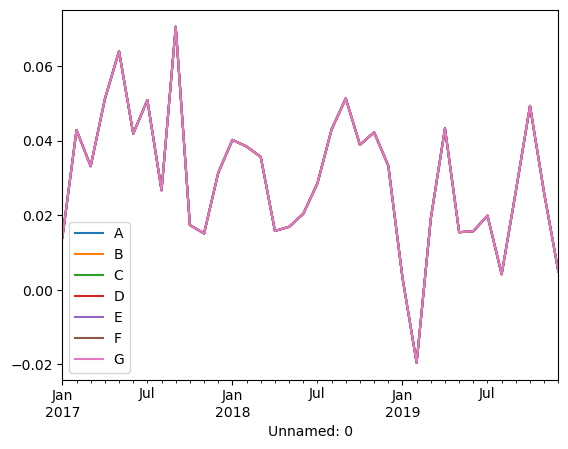

In [62]:
monthly_sea_surface_velocity = pd.read_csv("./monthly_surface_velocity.csv")
monthly_sea_surface_velocity = clean_csv(monthly_sea_surface_velocity)
monthly_sea_surface_velocity.plot()